# 01. Bangalore Housing & Traffic EDA with Local-Global Invariant IQR Preprocessing
**Project:** *Does Bangalore Traffic Explain House Prices? Uncertainty-Aware Price Prediction with Road-Network GNNs and Bayesian Heads*  
**Paper Grounding:** Ravichandran et al. (*Nature Scientific Reports*, 2025, 15:41208)  
**Method:** Algorithm 1: Local-Global Invariant Inter Quartile Range (IQR) & Min-Max Normalization

---
### Objectives:
1. Initialize centralized server and training logs.
2. Load the Bangalore Real Estate Listings dataset and Spatial Commute Matrix.
3. Implement and apply **Algorithm 1 (Local-Global Invariant IQR)** from the Nature 2025 paper to filter spatial outliers without overfitting.
4. Exploratory Data Analysis (EDA) on house prices, peak/off-peak travel times to the 5 major tech corridors, and metro proximity.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.logger import ServerLogger, log_system_telemetry
from src.gdag_preprocessing import LocalGlobalIQRPreprocessor

# Initialize live server logging
logger = ServerLogger.get_logger()
log_system_telemetry()
logger.info("Notebook 01: Preprocessing & EDA initialized.")

23:51:48 [INFO] ================================================================================


23:51:48 [INFO] SYSTEM & SERVER TELEMETRY


23:51:48 [INFO] OS: win32 | Python: 3.11.9


23:51:48 [INFO] Host Memory: Total=15.69 GB | Available=3.13 GB (80.0% used)


23:51:48 [INFO] CPU Physical Cores: 10 | Logical Threads: 12


23:51:48 [INFO] ================================================================================


23:51:48 [INFO] Notebook 01: Preprocessing & EDA initialized.


## 1. Load Data Assets

In [2]:
# Load master spatial commute dataset
df_raw = pd.read_csv('../data/bangalore_housing_spatial_commute_dataset.csv')
df_hubs = pd.read_csv('../data/bangalore_tech_hubs.csv')
df_metro = pd.read_csv('../data/bangalore_metro_stations.csv')

print(f"Master Dataset Shape: {df_raw.shape}")
print(f"Number of Tech Hubs: {len(df_hubs)}")
print(f"Number of Operational Metro Stations: {len(df_metro)}")
df_hubs

Master Dataset Shape: (10008, 57)
Number of Tech Hubs: 5
Number of Operational Metro Stations: 64


,hub_id,hub_name,description,corridor,latitude,longitude
0,0,Whitefield,"ITPL, EPIP Zone, Export Promotion Industrial P...",East Tech Corridor,12.9840,77.7499
1,1,Bellandur_ORR,"Outer Ring Road, EcoSpace, Embassy TechVillage...",South-East ORR Corridor,12.9260,77.6762
2,2,Electronic_City,"Electronic City Phase 1 & 2, Infosys, Wipro, V...",South Highway Corridor,12.8452,77.6602
3,3,Manyata_Tech_Park,"Hebbal / Nagavara, Manyata Embassy Business Pa...",North Tech Corridor,13.0475,77.6214
4,4,MG_Road_CBD,"Central Business District, UB City, Brigade Ro...",Central Business District,12.9756,77.6066


## 2. Algorithm 1: Local-Global Invariant IQR Preprocessing
As formulated in Eq. (5) & (8) of Ravichandran et al. (Nature 2025):
$$ResO = X(IQR) = X(Q_3) - X(Q_1)$$
Filtered bounds: $[Q_1 - 1.5 	imes IQR, Q_3 + 1.5 	imes IQR]$ evaluated both globally and conditioned on local sub-environments (BHK and locality segments).

In [3]:
preprocessor = LocalGlobalIQRPreprocessor(iqr_multiplier=1.5)
df_clean = preprocessor.filter_outliers(df_raw, continuous_cols=['total_sqft_cleaned', 'price_per_sqft'])

print(f"Initial raw rows: {len(df_raw)}")
print(f"Cleaned rows:     {len(df_clean)}")
print(f"Retained:         {len(df_clean)/len(df_raw)*100:.2f}%")

23:51:49 [INFO] Applying Local-Global Invariant IQR filtering on 10008 initial records...


23:51:49 [INFO] Local-Global Invariant IQR filtering complete: Kept 8389 / 10008 records (1619 outliers removed, 83.82% retained)


Initial raw rows: 10008
Cleaned rows:     8389
Retained:         83.82%


## 3. Exploratory Data Analysis: Price vs. Commute Metrics

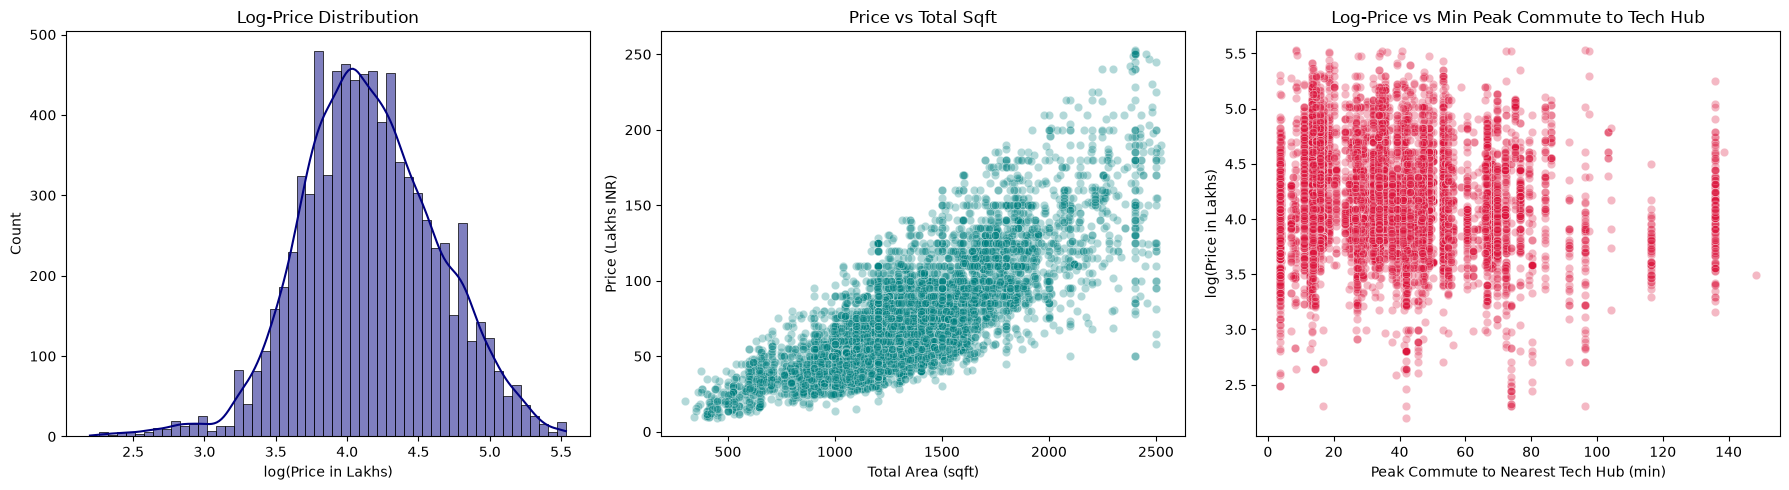

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of Log-Price
sns.histplot(df_clean['log_price'], kde=True, ax=axes[0], color='navy')
axes[0].set_title("Log-Price Distribution", fontsize=12)
axes[0].set_xlabel("log(Price in Lakhs)")

# Price vs Square Footage
sns.scatterplot(x='total_sqft_cleaned', y='price_lakhs', data=df_clean, alpha=0.3, ax=axes[1], color='teal')
axes[1].set_title("Price vs Total Sqft", fontsize=12)
axes[1].set_xlabel("Total Area (sqft)")
axes[1].set_ylabel("Price (Lakhs INR)")

# Price vs Min Peak Commute Time
sns.scatterplot(x='min_commute_peak_min', y='log_price', data=df_clean, alpha=0.3, ax=axes[2], color='crimson')
axes[2].set_title("Log-Price vs Min Peak Commute to Tech Hub", fontsize=12)
axes[2].set_xlabel("Peak Commute to Nearest Tech Hub (min)")
axes[2].set_ylabel("log(Price in Lakhs)")

plt.tight_layout()
plt.show()

## 4. Corridor Congestion Analysis: Peak vs. Off-Peak Friction

In [5]:
corridors = ['whitefield', 'bellandur_orr', 'electronic_city', 'manyata_tech_park', 'mg_road_cbd']
congestion_summary = []

for c in corridors:
    peak_col = f"commute_{c}_peak_min"
    offpeak_col = f"commute_{c}_offpeak_min"
    ratio_col = f"congestion_ratio_{c}"
    congestion_summary.append({
        "Corridor": c.replace('_', ' ').title(),
        "Mean Off-Peak (min)": df_clean[offpeak_col].mean(),
        "Mean Peak (min)": df_clean[peak_col].mean(),
        "Mean Congestion Ratio": df_clean[ratio_col].mean()
    })

pd.DataFrame(congestion_summary)

,Corridor,Mean Off-Peak (min),Mean Peak (min),Mean Congestion Ratio
0,Whitefield,42.113196,104.708571,2.499930
1,Bellandur Orr,31.403219,79.125665,2.519841
2,Electronic City,33.870795,78.851073,2.301105
3,Manyata Tech Park,36.553713,85.002688,2.318081
4,Mg Road Cbd,36.217153,74.418703,2.061324


## 5. Summary & Server Log Checkpoint

In [6]:
logger.info(f"Notebook 01 execution completed. Verified {len(df_clean)} cleaned listings.")
print("Check logs/server.log and logs/training.log to view live backend logs.")

23:51:50 [INFO] Notebook 01 execution completed. Verified 8389 cleaned listings.


Check logs/server.log and logs/training.log to view live backend logs.
